# TS06 — Compact MLP, LSTM, GRU and causal TCN forecasting

## Goal
Evaluate small neural networks with the same smoothed-input and target contracts as
TS05. Measure variability across three fixed seeds, use chronological early stopping,
and compare seed ensembles with baselines and frozen earlier procedures. Complexity
must earn its place through the saved evaluation; no architecture is presumed superior.

## Observed results

Four compact architectures were evaluated with three fixed seeds each and separate track selection. At five sessions, selected **returns** MSE skill is **0.0262** against **zero** over **30** scored origins. At five sessions, selected **smoothed** MSE skill is **0.1655** against **filter_nochange** over **30** scored origins. Seed variability is reported separately from historical sampling uncertainty. Results remain exploratory; no trading advantage is established.

## Setup
Requires PyTorch >=2.5 and scikit-learn >=1.6, alongside the prior dependencies.
All training uses CPU, one PyTorch thread and deterministic algorithms. Each fit starts
from scratch. Exact results may differ across library versions or hardware even with
the same seed. No model download, GPU or previous notebook execution is required.

In [1]:
from pathlib import Path
import sys,json
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'src'/'tslab').is_dir())
sys.path.insert(0,str(ROOT/'src'))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dataclasses import asdict
from IPython.display import display,Markdown
from tslab.data import load_snapshot
from tslab.supervised import FeatureSpec,SupervisedData,ema_anchor,chronological_holdout
from tslab.learned_evaluation import LearnedRunner,nested_learned
from tslab.evaluation import scorecard
from tslab.learning_reports import export_learning,frozen_comparison
from tslab.provenance3 import write_learning_manifest
from tslab.reporting import configure_plots,save_figure
configure_plots()
SEED=1731
OUT=ROOT/'outputs'/'TS06_Compact_Neural_Forecasting';OUT.mkdir(parents=True,exist_ok=True)
market_x,metadata=load_snapshot(ROOT/'inputs'/'SPY_adjusted_demo.csv',ROOT/'inputs'/'SPY_adjusted_demo.metadata.json')
features=FeatureSpec(lookback=20,fast_alpha=.2,slow_alpha=.05,warmup=120)
settings=dict(outer_starts=(1000,1400,1800),outer_step=40,inner_count=3,inner_step=40,max_samples=252,min_success=.8)
REF=ROOT/'inputs'/'learning_references'
reference_metadata=json.loads((REF/'metadata.json').read_text())

## Steps
### 1. Declare architectures, seeds and training budget
Each track has its own five-output network. The input is a 20-by-2 window of causal
EMA increments; the smoothed track predicts residuals above its mechanical anchor,
and the return track directly predicts actual cumulative log returns.

MLP flattens the lag window. LSTM/GRU use one unidirectional recurrent layer and the
last hidden output. The causal TCN uses left padding and dilations 1,2,4,8, giving
receptive field 31 observations (covering the 20-position window with zero left padding).
No right-padding leakage, bidirectional state or future teacher forcing is used.

In [2]:
import torch
from tslab.neural import neural_models,ForecastNet,fit_neural,NeuralFit
models=neural_models()
seeds=(1731,1732,1733)
catalogue=[]
for model in models:
    network=ForecastNet(model,features.lookback,2)
    catalogue.append({**asdict(model),'parameter_count':sum(p.numel() for p in network.parameters()),
                      'seed_count':len(seeds),'input_shape':'20 x 2','output_count':5})
catalogue=pd.DataFrame(catalogue)
catalogue.to_csv(OUT/'architecture_catalogue.csv',index=False)
display(catalogue)
print('PyTorch:',torch.__version__,'; fixed seeds:',seeds)
print('AdamW; learning rate .005; weight decay .001; gradient norm capped at 1; full-batch training.')

PyTorch: 2.5.1 ; fixed seeds: (1731, 1732, 1733)
AdamW; learning rate .005; weight decay .001; gradient norm capped at 1; full-batch training.


,name,family,hidden,max_epochs,patience,learning_rate,weight_decay,validation_fraction,parameter_count,seed_count,input_shape,output_count
0,MLP,mlp,12,30,5,0.005,0.001,0.2,713,3,20 x 2,5
1,LSTM,lstm,12,30,5,0.005,0.001,0.2,833,3,20 x 2,5
2,GRU,gru,12,30,5,0.005,0.001,0.2,641,3,20 x 2,5
3,CausalTCN,tcn,12,30,5,0.005,0.001,0.2,1481,3,20 x 2,5


### 2. Purge the chronological stopping split
For each available training pool, reserve its last 20% of feature origins for stopping.
Optimization-training examples must have their full five-session labels end **before**
the first validation feature origin. Overlapping trailing input histories are allowed;
unavailable future labels are not. Stopping-stage scalers use optimization rows only.

Choose the epoch count with minimum chronological validation loss within a maximum
of 30 epochs and patience 5. Then reset the same seed, refit scalers on all mature
examples, and train a fresh network for exactly that many epochs. This uses no future
observation beyond the current forecast origin. The loss is mean MSE across individually
standardized horizon targets; outer model selection still uses relative MAE.

In [3]:
dataset=SupervisedData(market_x,features)
X,y,origins=dataset.training(999,'returns',settings['max_samples'])
train,val=chronological_holdout(origins)
split_table=pd.DataFrame([{'stage':'optimization','rows':len(train),
    'first_feature':market_x.index[origins[train[0]]],'last_label':market_x.index[origins[train[-1]]+5]},
    {'stage':'stopping validation','rows':len(val),'first_feature':market_x.index[origins[val[0]]],
     'last_label':market_x.index[origins[val[-1]]+5]}])
split_table.to_csv(OUT/'chronological_stopping_split.csv',index=False)
display(split_table)
assert origins[train[-1]]+5<origins[val[0]]
assert origins[val[-1]]+5<=999

,stage,rows,first_feature,last_label
0,optimization,196,2020-12-14,2021-09-30
1,stopping validation,51,2021-10-01,2021-12-20


### 3. Evaluate fixed seed ensembles chronologically
At every inner and outer origin, fit all four architectures for both tracks with all
three seeds. Average the three predictions within each architecture; do not select
the best seed. If any seed fails, the architecture uses the predeclared baseline
fallback and records the incomplete ensemble. Individual seed results remain available.

Selection is separate by track and frozen within each outer block. The baseline is
always eligible. The 30 scored outer origins and training budget match TS05.

Completed neural block 1/3; choices: {'smoothed': 'MLP', 'returns': 'MLP'}
Completed neural block 2/3; choices: {'smoothed': 'GRU', 'returns': 'zero'}
Completed neural block 3/3; choices: {'smoothed': 'GRU', 'returns': 'zero'}
Out[1]: PosixPath('/Users/trush/.codex/.chatgpt-projects/g-p-6ac01b41a6988191a4168a93e414b122/forecasting_library/outputs/TS06_Compact_Neural_Forecasting/01_separate_outer_scorecards.png')


,block,track,chosen_model,selection_cutoff,inner_last_label
0,0,smoothed,MLP,2021-12-20,2021-12-20
1,0,returns,MLP,2021-12-20,2021-12-20
2,1,smoothed,GRU,2023-07-26,2023-07-26
3,1,returns,zero,2023-07-26,2023-07-26
4,2,smoothed,GRU,2025-02-28,2025-02-28
5,2,returns,zero,2025-02-28,2025-02-28


,model,n,RMSE,MSE_skill
76,CausalTCN,30,0.009043,0.181001
77,GRU,30,0.009126,0.165996
78,LSTM,30,0.009139,0.163678
79,MLP,30,0.009083,0.173811
80,filter_drift,30,0.009004,0.188215
81,filter_nochange,30,0.009993,0.000000
82,persistence,30,0.016358,-1.679768
83,selected_pipeline,30,0.009129,0.165474
84,smooth_slope,30,0.013520,-0.830494


,model,n,RMSE,MSE_skill
32,CausalTCN,30,0.018357,0.139713
33,GRU,30,0.018519,0.124467
34,LSTM,30,0.018401,0.135573
35,MLP,30,0.018406,0.135130
36,raw_drift,30,0.018479,0.128267
37,selected_pipeline,30,0.019530,0.026234
38,smooth_slope,30,0.028919,-1.135087
39,zero,30,0.019791,0.000000


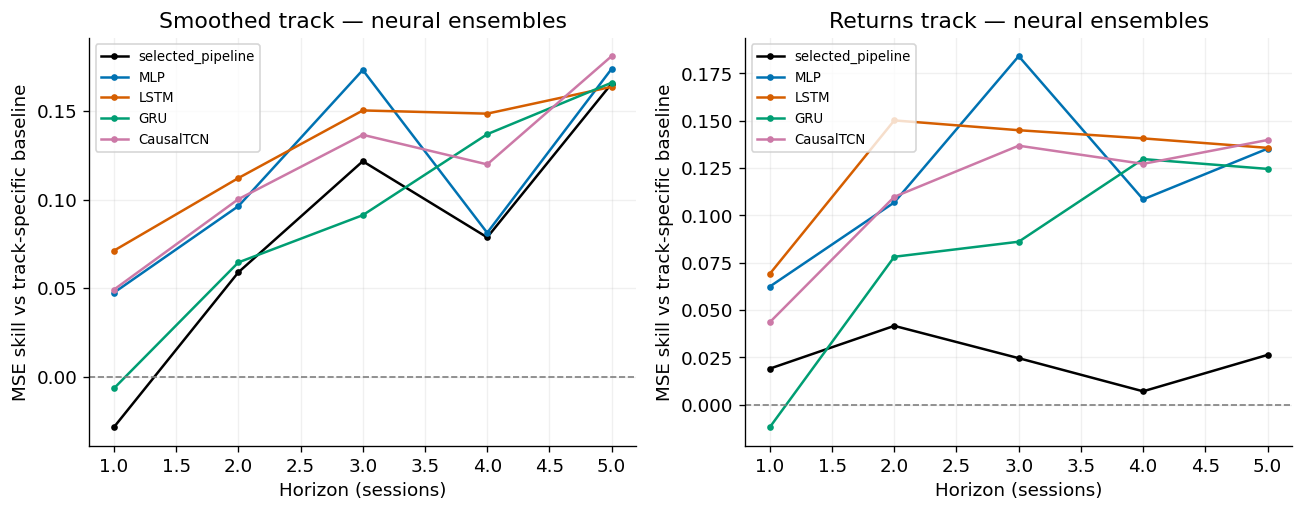

In [4]:
run=nested_learned(market_x,models,mode='neural',feature_spec=features,seeds=seeds,
    checkpoint_dir=OUT/'checkpoints',**settings,progress=True)
scores,uncertainty=export_learning(run,OUT)
records=run['forecasts']
display(run['selections'][['block','track','chosen_model','selection_cutoff','inner_last_label']])
for track in ['smoothed','returns']:
    display(scores.query('track==@track and horizon==5')[['model','n','RMSE','MSE_skill']].round(6))
colors={'selected_pipeline':'black','MLP':'#0072B2','LSTM':'#D55E00','GRU':'#009E73','CausalTCN':'#CC79A7'}
fig,axes=plt.subplots(1,2,figsize=(11,4.4))
for ax,track in zip(axes,['smoothed','returns']):
    for name in colors:
        part=scores[(scores.track==track)&(scores.model==name)]
        ax.plot(part.horizon,part.MSE_skill,'o-',ms=3,color=colors[name],label=name)
    ax.axhline(0,color='.5',ls='--',lw=1)
    ax.set(title=f'{track.title()} track — neural ensembles',xlabel='Horizon (sessions)',ylabel='MSE skill vs track-specific baseline');ax.legend(fontsize=8)
save_figure(fig,OUT,'01_separate_outer_scorecards');

### 4. Inspect calibration learning curves and selected epoch counts
The representative curve is fixed in advance: GRU, return track, first seed, first
inner origin. It is not chosen for appearance or low outer error. Learning curves are
from the purged stopping stage; final refits reset the model and use the chosen epoch
count. All stopping traces are exported for audit.

Out[1]: PosixPath('/Users/trush/.codex/.chatgpt-projects/g-p-6ac01b41a6988191a4168a93e414b122/forecasting_library/outputs/TS06_Compact_Neural_Forecasting/02_learning_curves_and_stopping.png')


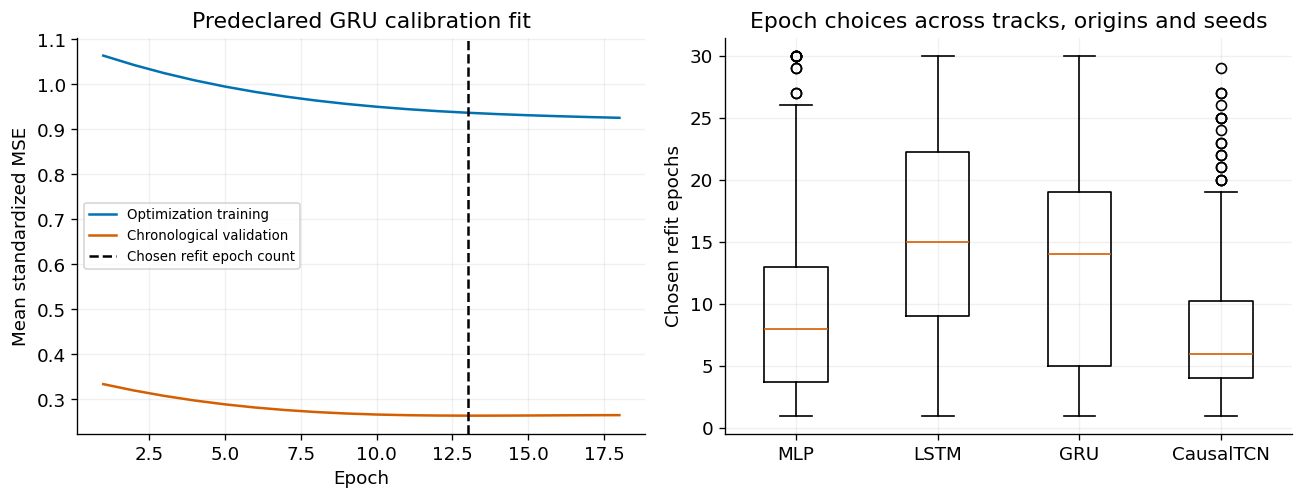

In [5]:
curves=run['learning_curves']
first_origin=curves.origin_pos.min()
part=curves[(curves.model=='GRU')&(curves.track=='returns')&(curves.seed==seeds[0])&(curves.origin_pos==first_origin)]
audit=run['fit_audit']
seed_audit=audit[audit.seed.astype(str)!='ensemble'].copy()
fig,axes=plt.subplots(1,2,figsize=(11,4.3))
axes[0].plot(part.epoch,part.training_MSE_standardized,label='Optimization training')
axes[0].plot(part.epoch,part.validation_MSE_standardized,label='Chronological validation')
chosen=seed_audit[(seed_audit.model=='GRU')&(seed_audit.track=='returns')&(seed_audit.seed.astype(str)==str(seeds[0]))&(seed_audit.origin_pos==first_origin)].chosen_epochs.iloc[0]
axes[0].axvline(chosen,color='black',ls='--',label='Chosen refit epoch count')
axes[0].set(title='Predeclared GRU calibration fit',xlabel='Epoch',ylabel='Mean standardized MSE');axes[0].legend(fontsize=8)
names=[m.name for m in models]
epoch_values=[seed_audit.loc[seed_audit.model==name,'chosen_epochs'].dropna() for name in names]
axes[1].boxplot(epoch_values,tick_labels=names,showfliers=True)
axes[1].set(title='Epoch choices across tracks, origins and seeds',ylabel='Chosen refit epochs')
save_figure(fig,OUT,'02_learning_curves_and_stopping');

### 5. Quantify seed variability without calling it a confidence interval
Show each fixed seed's five-session outer score beside the three-seed ensemble.
These variations reflect training initialization under this fixed data/architecture,
not independent market experiments, forecast intervals or statistical confidence.
Selection uses ensemble predictions only; no favorable seed is promoted.

Out[1]: PosixPath('/Users/trush/.codex/.chatgpt-projects/g-p-6ac01b41a6988191a4168a93e414b122/forecasting_library/outputs/TS06_Compact_Neural_Forecasting/03_seed_variability.png')


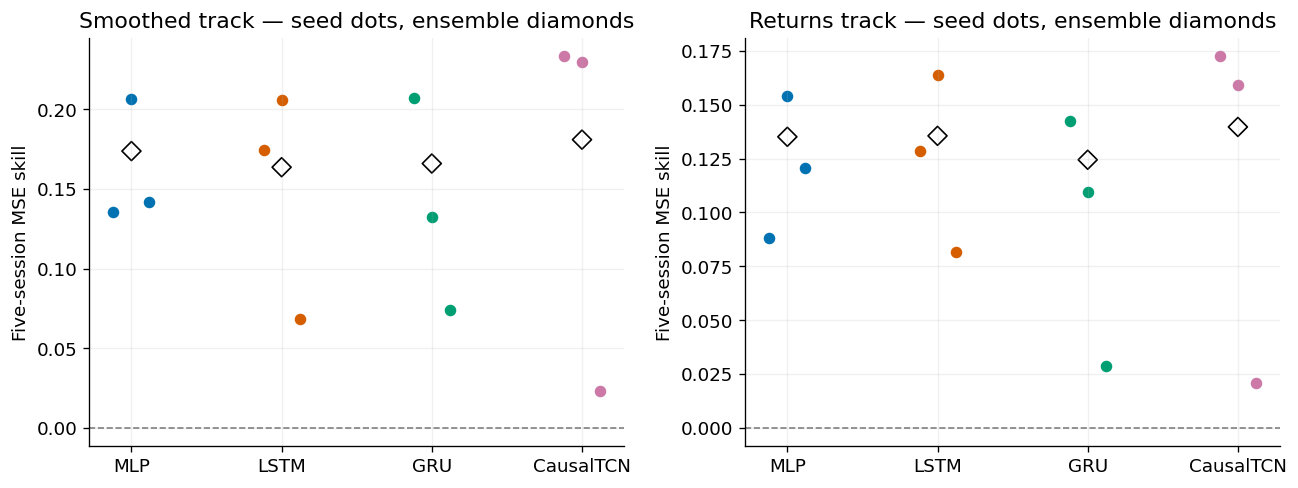

In [6]:
seed_scores=pd.read_csv(OUT/'seed_scorecards.csv')
fig,axes=plt.subplots(1,2,figsize=(11,4.2))
for ax,track in zip(axes,['smoothed','returns']):
    for position,name in enumerate(names):
        part=seed_scores[(seed_scores.track==track)&(seed_scores.family==name)&(seed_scores.horizon==5)].sort_values('seed')
        ax.scatter(position+np.linspace(-.12,.12,len(part)),part.MSE_skill,color=colors[name],s=35)
        ensemble=scores[(scores.track==track)&(scores.model==name)&(scores.horizon==5)].MSE_skill.iloc[0]
        ax.scatter(position,ensemble,marker='D',s=65,facecolors='none',edgecolors='black')
    ax.axhline(0,color='.5',ls='--',lw=1);ax.set_xticks(range(len(names)),names)
    ax.set(title=f'{track.title()} track — seed dots, ensemble diamonds',ylabel='Five-session MSE skill')
save_figure(fig,OUT,'03_seed_variability');

### 6. Compare complete procedures on matched dates
TS04 and TS05 references preserve their delivered block choices. Target values and
dates are checked before comparison. TS04 used different training and selection
budgets; these curves compare procedures, not isolated effects of architecture.
The reference files are frozen: rerunning another notebook does not silently replace them.

Out[1]: PosixPath('/Users/trush/.codex/.chatgpt-projects/g-p-6ac01b41a6988191a4168a93e414b122/forecasting_library/outputs/TS06_Compact_Neural_Forecasting/04_matched_pipeline_comparison.png')


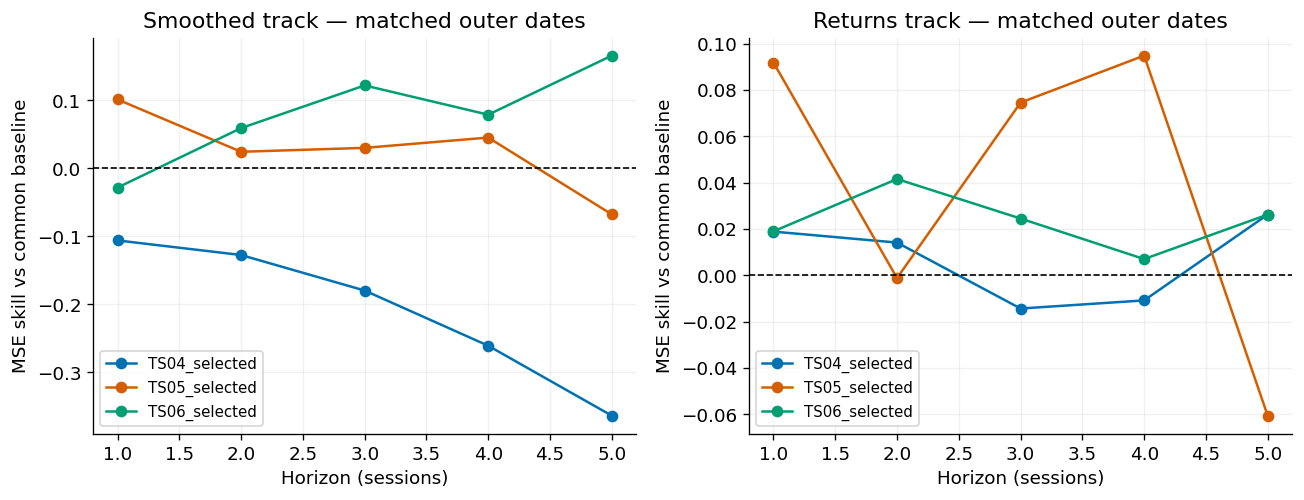

In [7]:
comparison=frozen_comparison(records,{'TS04_selected':REF/'TS04_selected.csv','TS05_selected':REF/'TS05_selected.csv'},
                            REF/'metadata.json','TS06_selected')
comparison.to_csv(OUT/'matched_prior_pipeline_comparison.csv',index=False)
fig,axes=plt.subplots(1,2,figsize=(11,4.3))
for ax,track in zip(axes,['smoothed','returns']):
    for name in ['TS04_selected','TS05_selected','TS06_selected']:
        part=comparison[(comparison.track==track)&(comparison.model==name)]
        ax.plot(part.horizon,part.MSE_skill,'o-',label=name)
    ax.axhline(0,color='black',ls='--',lw=1)
    ax.set(title=f'{track.title()} track — matched outer dates',xlabel='Horizon (sessions)',ylabel='MSE skill vs common baseline');ax.legend(fontsize=9)
save_figure(fig,OUT,'04_matched_pipeline_comparison');

### 7. Keep dependence-aware uncertainty attached to the selected procedure
These moving-block percentile ranges compare selected-minus-baseline absolute loss
at horizon five. Blocks count scheduled origins (40 sessions apart here), not days.
They reflect the stated historical resampling assumptions, not corrections for prior
project exploration or repeated model searches.

Out[1]: PosixPath('/Users/trush/.codex/.chatgpt-projects/g-p-6ac01b41a6988191a4168a93e414b122/forecasting_library/outputs/TS06_Compact_Neural_Forecasting/05_paired_uncertainty.png')


,track,mean_MAE_difference,lower95,upper95,n_origins,block_origins,draws
0,smoothed,-0.000823,-0.001397,-0.000270,30,1,2000
1,smoothed,-0.000823,-0.001405,-0.000173,30,2,2000
2,smoothed,-0.000823,-0.001514,-0.000075,30,4,2000
3,returns,-0.000024,-0.000883,0.000776,30,1,2000
4,returns,-0.000024,-0.000566,0.000905,30,2,2000
5,returns,-0.000024,-0.000206,0.000857,30,4,2000


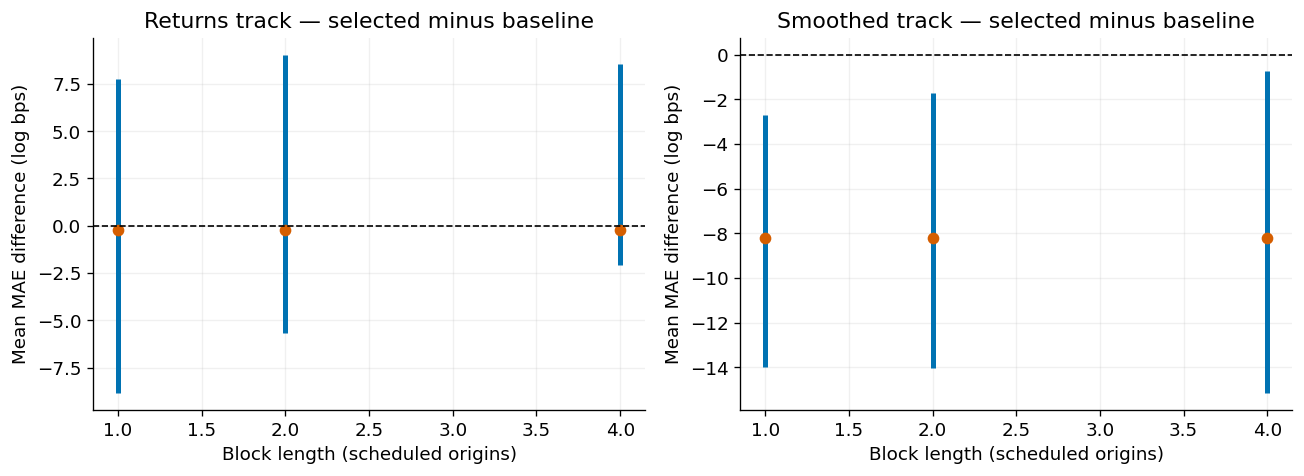

In [8]:
display(uncertainty.round(7))
fig,axes=plt.subplots(1,2,figsize=(11,4.1))
for ax,(track,part) in zip(axes,uncertainty.groupby('track')):
    ax.vlines(part.block_origins,part.lower95*1e4,part.upper95*1e4,lw=3)
    ax.plot(part.block_origins,part.mean_MAE_difference*1e4,'o',color='#D55E00')
    ax.axhline(0,color='black',ls='--',lw=1)
    ax.set(title=f'{track.title()} track — selected minus baseline',xlabel='Block length (scheduled origins)',ylabel='Mean MAE difference (log bps)')
save_figure(fig,OUT,'05_paired_uncertainty');

## Checks
Check purged stopping-label timing, mature final-refit labels, frozen selection,
all-seed averaging, and restored checkpoint predictions. The full tests additionally
verify deterministic repeat fits, causal TCN padding and future-poisoned prefix forecasts.
Checkpoints use plain tensor/state dictionaries and load with `weights_only=True`.

In [9]:
assert (audit.max_training_label<=audit.origin_pos).all()
valid=seed_audit[seed_audit.fit_status=='ok']
assert (valid.optimization_last_label<valid.validation_first_origin).all()
assert (valid.last_training_label<=valid.origin_pos).all()
assert (run['selections'].inner_last_label<=run['selections'].selection_cutoff).all()
assert records[records.origin==market_x.index[-1]].status.eq('immature').all()
checkpoint_checks=[]
for path in sorted((OUT/'checkpoints').glob('*.pt')):
    state=torch.load(path,map_location='cpu',weights_only=True)
    restored=NeuralFit.restore(state)
    prediction=restored.predict(state['sequence'].numpy())
    np.testing.assert_array_equal(prediction,state['residual_prediction'].numpy())
    checkpoint_checks.append({'checkpoint':path.name,'restored_prediction_equal':True})
pd.DataFrame(checkpoint_checks).to_csv(OUT/'checkpoint_checks.csv',index=False)
assert len(checkpoint_checks)==len(models)*len(seeds)*2
write_learning_manifest(OUT,{'features':asdict(features),'models':[asdict(m) for m in models],**settings,
    'seeds':list(seeds),'seed_policy':'equal-weight complete ensemble; never best-seed selection',
    'training':'deterministic CPU, full batch AdamW, purged chronological stopping, reset/refit all mature rows'},
    {'market':metadata,'references':reference_metadata},neural=True,seed=SEED)
selected=scores.query("model=='selected_pipeline' and horizon==5")
summary='## Observed results'+chr(10)*2+'Four compact architectures were evaluated with three fixed seeds each and separate track selection. '
for row in selected.itertuples():summary+=f"At five sessions, selected **{row.track}** MSE skill is **{row.MSE_skill:.4f}** against **{row.baseline}** over **{row.n}** scored origins. "
summary+='Seed variability is reported separately from historical sampling uncertainty. Results remain exploratory; no trading advantage is established.'
(OUT/'observed_summary.md').write_text(summary)
print('PASS: stopping split, mature labels, frozen selection and all checkpoint round trips.')

PASS: stopping split, mature labels, frozen selection and all checkpoint round trips.


## Next Steps
TS07 can demonstrate larger architectures under the same contracts. Wider tuning,
more seeds, additional assets and an untouched prospective period are separate
experiments. A model's complexity or stable training does not establish market skill.

References: [PyTorch LSTM](https://docs.pytorch.org/docs/stable/generated/torch.nn.LSTM.html),
[GRU](https://docs.pytorch.org/docs/stable/generated/torch.nn.GRU.html),
[reproducibility](https://docs.pytorch.org/docs/stable/notes/randomness.html).